<a href="https://colab.research.google.com/github/santhoshkumar2006/emergency/blob/main/emergency.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Data Cleaning, Sequential Window Creation, and Splitting
We will clean up the hourly data, fill any gaps created during the resampling process, scale features, and create sequential windows suitable for a Recurrent Neural Network (LSTM).

In [7]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Combine hourly_X and hourly_y
df_hourly = hourly_X.copy()
df_hourly['Congestion_Index'] = hourly_y.values

# Drop columns containing all NaNs or non-numeric metadata that aren't useful
df_hourly = df_hourly.dropna(how='all')
df_hourly = df_hourly.select_dtypes(include=[np.number])

# Forward fill and backward fill any remaining NaNs to maintain temporal continuity
df_hourly = df_hourly.ffill().bfill()

# Split into features and target
y_col = 'Congestion_Index'
X_cols = [c for c in df_hourly.columns if c != y_col]

# Scale the features and target
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_scaled = scaler_X.fit_transform(df_hourly[X_cols])
y_scaled = scaler_y.fit_transform(df_hourly[[y_col]]).flatten()

# Create sequences for LSTM (e.g., lookback of 12 hours to predict the next hour)
def create_sequences(X, y, time_steps=12):
    Xs, ys = [], []
    for i in range(len(X) - time_steps):
        Xs.append(X[i:(i + time_steps)])
        ys.append(y[i + time_steps])
    return np.array(Xs), np.array(ys)

TIME_STEPS = 12
X_seq, y_seq = create_sequences(X_scaled, y_scaled, TIME_STEPS)

# Train-test split (80% train, 20% test chronologically)
split_idx = int(len(X_seq) * 0.8)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Train shape: (1331, 12, 58), Test shape: (333, 12, 58)


### 2. Model Selection, Training, and Evaluation
We select an LSTM (Long Short-Term Memory) network because it natively handles temporal dependencies and sequence structures in time-series traffic data.

In [8]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# Build the LSTM model
model = Sequential([
    LSTM(64, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.summary()

# Train the model
history = model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        31,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,601 (131.25 KB)

 Trainable params: 33,601 (131.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.7943 - val_loss: 0.5112
Epoch 2/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5255 - val_loss: 0.4347
Epoch 3/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4421 - val_loss: 0.3869
Epoch 4/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.3823 - val_loss: 0.3414
Epoch 5/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.3471 - val_loss: 0.2965
Epoch 6/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.3116 - val_loss: 0.3039
Epoch 7/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.2701 - val_loss: 0.2725
Epoch 8/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.2541 - val_loss: 0.2720
Epoch 9/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.2512 - val_loss: 0.2622
Epoch 10/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.2098 - val_loss: 0.2445
Epoch 11/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.2028 - val_loss: 0.2487
Epoch 12/30
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - loss: 0.2

In [9]:
# Predict and inverse scale
y_pred_scaled = model.predict(X_test)
y_pred = scaler_y.inverse_transform(y_pred_scaled).flatten()
y_test_orig = scaler_y.inverse_transform(y_test.reshape(-1, 1)).flatten()

# Calculate metrics
mae = mean_absolute_error(y_test_orig, y_pred)
rmse = root_mean_squared_error(y_test_orig, y_pred)

print(f"Test Mean Absolute Error (MAE): {mae:.4f}")
print(f"Test Root Mean Squared Error (RMSE): {rmse:.4f}")

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Test Mean Absolute Error (MAE): 11.4388
Test Root Mean Squared Error (RMSE): 15.9260


### 3. Plot Actual vs Predicted Congestion Values

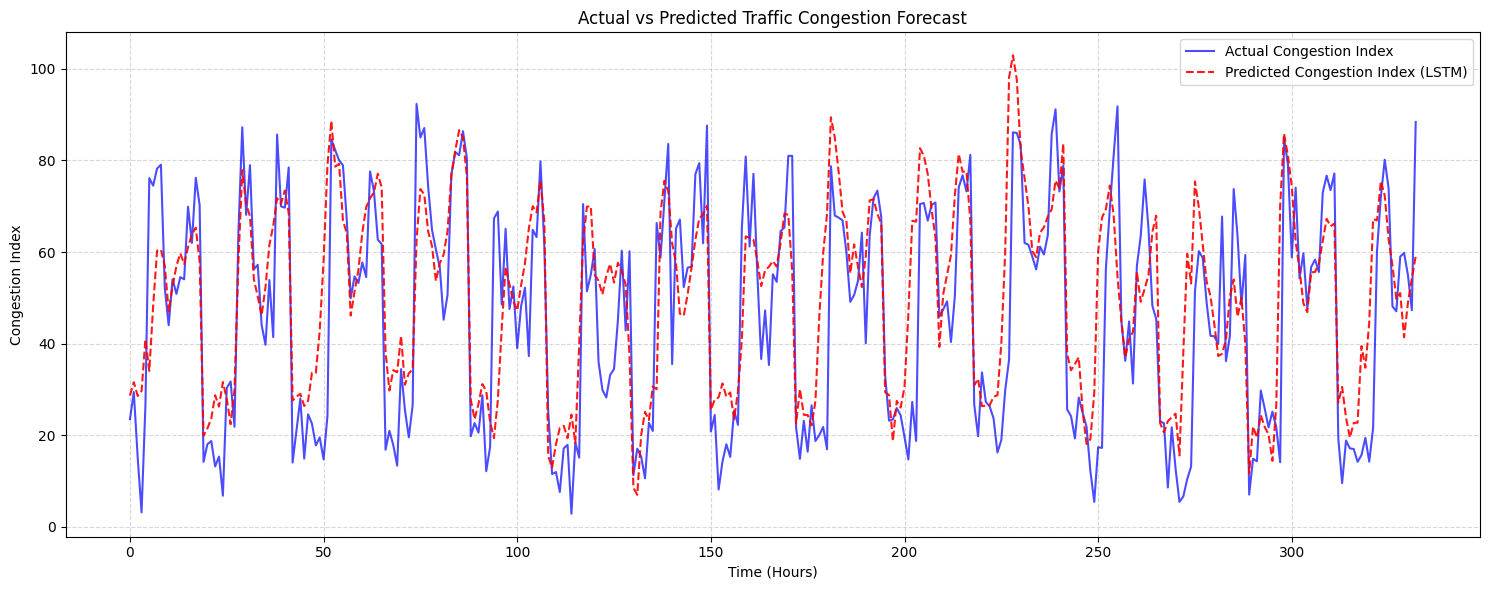

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))
plt.plot(y_test_orig, label='Actual Congestion Index', color='blue', alpha=0.7)
plt.plot(y_pred, label='Predicted Congestion Index (LSTM)', color='red', linestyle='--', alpha=0.9)
plt.title('Actual vs Predicted Traffic Congestion Forecast')
plt.xlabel('Time (Hours)')
plt.ylabel('Congestion Index')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()